In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from Bio import SeqIO
import os

def get_df(fasta_file):
  
    record_dict = SeqIO.to_dict(SeqIO.parse(fasta_file, "fasta"))
    sequence_list_original = [str(record.seq) for record in record_dict.valTes() if 12 <= len(record.seq) <= 44]
    # sequence_list_original = [str(record.seq) for record in record_dict.values()]
    df = pd.DataFrame(sequence_list_original, columns=["sequence"])
    num_lines = len(df)
    # print(f"The number of sequences is: {num_lines}")
    # print("original mirdeep2 sequences:\t", df)
    # df.sort_values(by="sequence", inplace=True)
    # df.drop_duplicates(subset=["sequence"], inplace=True)
    # df.reset_index(drop=True, inplace=True)
    sequence_list = [len(seq) for seq in df['sequence']]
    # print(sequence_list)

    value_counts = pd.Series(sequence_list).value_counts().sort_index()
    # print(value_counts)
  
    df_final = value_counts.reset_index()

    df_final.columns = ['length', 'count']
    return df_final

def main():
    # fasta_file_1 = "sequence_length_3rd_samples/final_seq_12_831.fasta" 
    # df_1 = get_df(fasta_file_1)
    # print(df_1)
    # fasta_file_2 = "sequence_length_3rd_samples/final_seq_12_832.fasta" 
    # df_2 = get_df(fasta_file_2)
    # print(df_2)
    # fasta_file_3 = "sequence_length_3rd_samples/final_seq_12_833.fasta" 
    # df_3 = get_df(fasta_file_3)
    # print(df_3)
    # # Example DataFrame structure
    # # data = {
    # #     'Length': list(range(15, 31)) * 3,
    # #     'Reads': [8, 7, 6, 5, 4, 4, 3, 3, 2, 2, 1, 1, 0.5, 0.5, 0.2, 0.2] * 3,
    # #     'Sample': ['SBH49'] * 16 + ['SBH149'] * 16 + ['SBH372'] * 16
    # # }
    # data = {
    #     'Length': df_1['length'].to_list() + df_2['length'].to_list() + df_3['length'].to_list(),
    #     'Reads': df_1['count'].to_list() + df_2['count'].to_list() + df_3['count'].to_list(),
    #     'Sample': ['SRR20723831'] * len(df_1['length']) + ['SRR20723832'] * len(df_2['length']) + ['SRR20723833'] * len(df_3['length'])
    # }
    
    base_path = "../../../../4th_3samples_output"
    total_names = [
        "SRR25896993", "SRR25896994", "SRR25896995"
    ]
    # group_name = ["DSS 1","DSS 2","DSS 3","control 1","control 2","control 3"]
    all_lengths = []
    all_counts = []
    all_samples = []
    # folder_path = "sequence_length_5th_samples"
 
    color_list = [  '#1f77b4',  # Blue
                    '#ff7f0e',  # Orange
                    '#2ca02c',  # Green
                    '#d62728',  # Red
                    '#9467bd',  # Purple
                    '#8c564b',  # Brown
                    '#e377c2',  # Pink
                    '#7f7f7f',  # Gray
                    '#bcbd22']  # Yellow-green
    # color_list = ['#1f77b4', '#ff7f0e', '#2ca02c']
  
    for i,name in enumerate(total_names):
        # if file_name.endswith(".fasta"):  # Process only FASTA files
        fasta_file = os.path.join(base_path, name, "extract/final_seq_12.fasta")
        # df = pd.read_csv(file_path, sep=',', usecols=[2,4]).head(10)
        # fasta_file = os.path.join(folder_path, file_name)
        

        df = get_df(fasta_file)
        print(f"Processed: {fasta_file}")
        print(df)
        
        # Extract sample name from the file name (e.g., 'final_seq_12_831.fasta' -> 'SRR20723831')
        sample_name = name
        

        all_lengths.extend(df['length'].to_list())
        all_counts.extend(df['count'].to_list())
        all_samples.extend([sample_name] * len(df['length']))

    data = {
        'Length': all_lengths,
        'Reads': all_counts,
        'Sample': all_samples
    }
    df = pd.DataFrame(data)


    sns.set(style="whitegrid", font_scale=1.2)

    plt.figure(figsize=(12, 6)) 
    ax = sns.barplot(
        x='Length', 
        y='Reads', 
        hue='Sample', 
        data=df, 
        errorbar=None, 
        palette=color_list
    )


    ax.set_xlabel("Length (nt)", fontsize=14, weight='bold')
    ax.set_ylabel("Number of Reads (x10^6)", fontsize=14, weight='bold')
    ax.set_title("Read Distribution by Length", fontsize=16, weight='bold')


    ax.legend(title="Sample", fontsize=12, title_fontsize=14, loc='upper right')


    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    #plt.show()
    plt.savefig(os.path.join(base_path, "4th_samples_after_clean_12_length_plot.png") , format='png', dpi=300, bbox_inches='tight')
    plt.close() 

if __name__ == "__main__":
    main()

: 

: 

In [26]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from Bio import SeqIO
import os
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=20)

arial_font_in = fm.FontProperties(fname="arial.ttf", size=13)
print("aaa")
def get_df(fasta_file):

    # sequence_list_original = [str(record.seq) for record in record_dict.values()]
    df = pd.read_csv(fasta_file, sep=',', usecols=[0])
    # print("before")
    # print(len(df))
    df_temp = df.drop_duplicates()
    # print("after")
    # print(len(df_temp))
    # df = pd.DataFrame(sequence_list_original, columns=["sequence"])
    num_lines = len(df)
    # print(f"The number of sequences is: {num_lines}")
    # print("original mirdeep2 sequences:\t", df)
    # df.sort_values(by="sequence", inplace=True)
    # df.drop_duplicates(subset=["sequence"], inplace=True)
    # df.reset_index(drop=True, inplace=True)
    sequence_list = [len(seq) for seq in df['sequence']]
    # print(sequence_list)

    value_counts = pd.Series(sequence_list).value_counts().sort_index()
    #value_counts = pd.Series(sequence_list).value_counts()
    # print(value_counts)

    df_final = value_counts.reset_index()

    df_final.columns = ['length', 'count']
    return df_final

def main():
    # fasta_file_1 = "sequence_length_3rd_samples/final_seq_12_831.fasta" 
    # df_1 = get_df(fasta_file_1)
    # print(df_1)
    # fasta_file_2 = "sequence_length_3rd_samples/final_seq_12_832.fasta" 
    # df_2 = get_df(fasta_file_2)
    # print(df_2)
    # fasta_file_3 = "sequence_length_3rd_samples/final_seq_12_833.fasta" 
    # df_3 = get_df(fasta_file_3)
    # print(df_3)
    # # Example DataFrame structure
    # # data = {
    # #     'Length': list(range(15, 31)) * 3,
    # #     'Reads': [8, 7, 6, 5, 4, 4, 3, 3, 2, 2, 1, 1, 0.5, 0.5, 0.2, 0.2] * 3,
    # #     'Sample': ['SBH49'] * 16 + ['SBH149'] * 16 + ['SBH372'] * 16
    # # }
    # data = {
    #     'Length': df_1['length'].to_list() + df_2['length'].to_list() + df_3['length'].to_list(),
    #     'Reads': df_1['count'].to_list() + df_2['count'].to_list() + df_3['count'].to_list(),
    #     'Sample': ['SRR20723831'] * len(df_1['length']) + ['SRR20723832'] * len(df_2['length']) + ['SRR20723833'] * len(df_3['length'])
    # }
    # Initialize lists to build the final data dictionary
    base_path = "../../../../4th_3samples_output"
    code_path ="../../../../code/python/after_cleaning/analysis"
    total_names = [
        # "SRR25896993"
        "SRR25896993", "SRR25896994", "SRR25896995"
    ]
    # group_name = ["DSS 1","DSS 2","DSS 3","control 1","control 2","control 3"]
    all_lengths = []
    all_counts = []
    all_samples = []
    # folder_path = "sequence_length_5th_samples"
    # Define a color list with 9 different colors
    # color_list = [  '#1f77b4',  # Blue
    #                 '#ff7f0e',  # Orange
    #                 '#2ca02c',  # Green
    #                 '#d62728',  # Red
    #                 '#9467bd',  # Purple
    #                 '#8c564b',  # Brown
    #                 '#e377c2',  # Pink
    #                 '#7f7f7f',  # Gray
    #                 '#bcbd22']  # Yellow-green
    # color_list = [ "#C9A0DC",  # Adipose Tissue - light purple
    # "#87CEEB",  # Adrenal Gland - sky blue
    # "#FF9999",  # Blood - soft red
    # "#FFD700",  # Colon - light gold
    # "#A2CD5A",  # Kidney - light green
    # "#FF69B4",  # Liver - pink
    # "#DA70D6",  # Nerve - orchid
    # "#66CDAA",  # Ovary - aquamarine
    # "#BC8F8F"  # Pituitary - rosy brown
    # ]  
    # color_list =[
    #     "gray",
    #     "blue",
    #     "#bcbd22",
    #     "black",
    #     "red",
    #     "brown",
    #     "#1E90FF",
    #     "orange",
    #     "green"
    # ]# Yellow-green
    # color_list = [ 'orange','green',"blue" ]
    #    ("CGCGGGAUGGAGCAGUCUGGUAGC", "#e74c3c"),   # red
    # ("CGCGGGAUGGAGCAGUCUGGUAGCUCUGGCGCU", "#3498db"),  # blue
    # ("CGCGGGAUGGAGCAGUCUGGUAGCUCUGGCGGCUC", "#2ecc71"), # green
    # color_list = ["green","red", "blue"]
    color_list = [ "#3498db", "#e74c3c","#2ecc71"]
    # Loop through all files in the folder
    for i,name in enumerate(total_names):
        # if file_name.endswith(".fasta"):  # Process only FASTA files
        fasta_file = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        # df = pd.read_csv(file_path, sep=',', usecols=[2,4]).head(10)
        # fasta_file = os.path.join(folder_path, file_name)
        

        df = get_df(fasta_file)
        # print(f"Processed: {fasta_file}")
        # print(df)
        

        sample_name = name
        

        all_lengths.extend(df['length'].to_list())
        all_counts.extend(df['count'].to_list())
        all_samples.extend([sample_name] * len(df['length']))

    data = {
        'Length': all_lengths,
        'Reads': all_counts,
        'Sample': all_samples
    }
    df = pd.DataFrame(data)


    sns.set(style="whitegrid", font_scale=1.2)


    plt.figure(figsize=(12, 6))  
    ax = sns.barplot(
        x='Length', 
        y='Reads', 
        hue='Sample', 
        data=df, 
        errorbar=None, 
        palette=color_list  
    )


    ax.set_xlabel("Length (nt)", weight='bold',fontproperties=arial_font)
    ax.set_ylabel("Number of Reads", weight='bold',fontproperties=arial_font)
    ax.set_title("Read Distribution by Length", weight='bold',fontproperties=arial_font)


    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontproperties(arial_font)


    ax.legend(title="Sample", loc='upper right',
            prop=arial_font, title_fontproperties=arial_font)


    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    # plt.show()
    # plt.xticks(fontproperties=arial_font)
    plt.savefig("figure8_B.pdf", format="pdf", bbox_inches="tight")
    # plt.savefig(os.path.join(code_path, "5th_samples_after_all_step_length_plot.png") , format='png', dpi=300, bbox_inches='tight')
    plt.close() 

if __name__ == "__main__":
    main()

aaa


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from Bio import SeqIO
import os

In [3]:
#U TO T : CGCGGGAUGGAGCAGUCTGGUAGC -> CGCGGGATGGAGCAGTCTGGTAGC
base_path = "../../../../4th_3samples_output"
total_names = [
    "SRR25896993", "SRR25896994", "SRR25896995"
]
for i,name in enumerate(total_names):
    fasta_file = os.path.join(base_path, name, "produce_final_form/final_form.csv")
    df = pd.read_csv(fasta_file, sep=',')
    print(name)
    print(df[df['sequence'] == "CGCGGGATGGAGCAGTCTGGTAGC"])
    

# # for i,name in enumerate(total_names):
# fasta_file = os.path.join(base_path, "SRR25896993", "map_genome/blast_score_filter.txt")
# df = pd.read_csv(fasta_file, sep=',',header=None)
# print(df[0].head(5))
# print(df[df[0] == 2])



SRR25896993
                       sequence  mirBase  linearfold  mirdeep2  \
40243  CGCGGGATGGAGCAGTCTGGTAGC        1           0         0   

       representative_id  qseqid_count  \
40243             435076            80   

                                            same_seq_ids  
40243  435076|753352|1317851|2383512|3316485|3550725|...  
SRR25896994
                      sequence  mirBase  linearfold  mirdeep2  \
6415  CGCGGGATGGAGCAGTCTGGTAGC        1           0         0   

      representative_id  qseqid_count  \
6415              36206            72   

                                           same_seq_ids  
6415  36206|295822|452955|468250|2019649|2033337|265...  
SRR25896995
                       sequence  mirBase  linearfold  mirdeep2  \
28040  CGCGGGATGGAGCAGTCTGGTAGC        1           0         0   

       representative_id  qseqid_count  \
28040             238287            97   

                                            same_seq_ids  
28040  238287|593966|

In [ ]:
#sample id:SRR25896993
# 13797,1916465|1697012|1401879|3372367|25694376|1986533|6856433|9550270|14701815|18829698|15018001|4956406|18953396|12737631|302896|14528427|5963684|11882154|6253011|1779184|7902705|713467|182385|8301832|15355388|6950268|18764736|23827140|19363458|23740656|5933004|26308396|16180640|21773656|5663252|3862111|21845646|22887924|7156057|6638827|5707452|13594034|2482649|13171100|27931183|4032016|3996860|18359700|703351|5146282|14185723|10732845|21804245|19641633|23735602|7904972|4383438|11429075|196338|16574747|3084266|1864973|3245302|1444651|4563381|18197457|8494151|4673942|2056609|9257202|13763030|13306435|22930123|3288434|13754489|8080962|649320|1938151|1775308|12306391|25796270|4531063|5184373|21497012|1407564|10470589|1139479|1739812|7682175|1797189|1900428|828197|12878093|6616634|11900474|13163362|8497165|6061922|5539034|1365701|5688058|5006291|20385|12771713|8954530|16108505|3582034|1346592|5605800|17165031|2905361|145134|3334086|3131049|28619471|25369533|5123606|1048695|8680912|4305180|9816020|4771758|26812055|4776072|1044734|435076|1385373|528099|4005866|1294894|1069681|20599260|596196|25387408|162477|249543|2704744|3349381|7697009|449145|13052|5893267|5268191|11509243|4814782|1050857|271434|9167272|413725|5797413|27353073|22785044|3655126|4668830|19152642|496154|1898952|14601725|4608982|48636|8851283|3474742|14188165|5411597|3067979|1548579|30558|9983474|1328982|2033935|84048|206481|3202659|3269967|3148907|4542741|1288962|26748036|7359083|8152369|1609666|6533393|22821630|4537021|2411719|1449515|10458864|1173557|15072745|4162211|2288606|4723051|277436|2143026|3602342|15333948|10230126|2998400|3569382|13182797|25602125|639591|1677686|10565588|14383419|4990420|3864398|6269807|788465|325704|16284519|9221239|15986471|14898212|5782911|6616626|432875|20279586|13134374|6633913|5863667|67269|570119|3798241|9380547|10743226|2009589|2462653|20008994|953818|3616682|14170267|21524672|15828019|6023453|1932830|7358075|6633832|5256577|206017|4261843|23713862|9109366|18027212|1715067|681779|11799030|785847|1404295|1362581|6103128|3941678|1300234|9686971|597292|1555311|4092407|351281|279441|6741572|11851741|5618866|14010685|9965614|3426313|5456164|38665|590803|13288755|18370673|2968571|10145058|10599433|4967848|1102951|19121095|1276261|10870335|2110652|608315|5364981|795759|5419252|1026904|3053426|3858037|11871205|2159396|1515681|22824965|6434972|19538299|14607422|915207|18075546|16237806|16879236|10282123|15909544|24583580|1679304|19095596|5569290|2231330|5310648|4424143|11883073|27668084|7846477|24692435|9012183|1331123|11839469|20093151|2250207|1241111|14691825|26785460|1912590|2477764|5020930|18244935|9938095|3312311|1320704|2054326|8023153|382106|5709040|4553261|3381969|18157570|4122774|4009016|485852|13497501|71887|6232069|4134978|5627385|388956|17785182|10808823|23679512|344707|9106904|5865753|753834|1053988|4852254|21821094|981122|14089521|9655849|7132553|322266|19585270|1439266|14903960|20212667|1476068|8091820|14301628|2177516|10522248|12667050|5053042|23649308|2666381|398860|2096208|12373314|1620783|1124522|8644717|17194192|8857420|10542270|988775|7528216|17058792|5311644|6531906|6365679|7136906|5544395|3285268|26164781|1923992|3438304|35470|7505424|7358867|29136447|26209305|1940354|1329590|17495740|2340902|10990205|1768704|267886|8482676|3066627|10053162|3200099|7029866|2170799|4667456|12687661,1007330,1008074,745,3057,N,3,14000,13
13726,4771758|26812055|4776072|1044734|435076|1385373|528099|4005866|1294894|1069681|20599260|596196|25387408|162477|249543|2704744|3349381|7697009|449145|13052|5893267|5268191|11509243|4814782|1050857|271434|9167272|413725|5797413|27353073|22785044|3655126|4668830|19152642|496154|1898952|14601725|4608982|48636|8851283|3474742|14188165|5411597|3067979|1548579|30558|9983474|1328982|2033935|84048|206481|3202659|3269967|3148907|4542741|1288962|26748036|7359083|8152369|1609666|6533393|22821630|4537021|2411719|1449515|10458864|1173557|15072745|4162211,1007764,1007805,42,1018,N,2,N,28


In [ ]:
NC_002516.2	1007764	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAAC	1449515	1449515|2494776|10730538|11007131|16897969|17970648|26504268|27830436	8
NC_002516.2	1007764	1007790	AGTCTGGTAGCTCGTCGGGCTCATAAC	15072745	15072745|16536263	2
NC_002516.2	1007764	1007783	TAGCTCGTCGGGCTCATAAC	4162211	4162211|18299041	2
NC_002516.2	1007764	1007800	GGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAAC	1173557	1173557|9751300|14805781	3
NC_002516.2	1007764	1007781	GTTATGAGCCCGACGAGC	10458864	10458864	1
NC_002516.2	1007766	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATA	2411719	2411719	1
NC_002516.2	1007766	1007786	TATGAGCCCGACGAGCTACCA	4537021	4537021|12649508|12963115|17275514	4
NC_002516.2	1007766	1007800	GGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATA	22821630	22821630	1
NC_002516.2	1007767	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCAT	6533393	6533393	1
NC_002516.2	1007768	1007790	AGTCTGGTAGCTCGTCGGGCTCA	1609666	1609666|7191667|7294610|8435779|12410031|13427906|14514691|16496601	8
NC_002516.2	1007768	1007798	GATGGAGCAGTCTGGTAGCTCGTCGGGCTCA	8152369	8152369|23888240	2
NC_002516.2	1007768	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCA	7359083	7359083|9351058|12683225|14797187|26308471	5
NC_002516.2	1007768	1007786	TGGTAGCTCGTCGGGCTCA	26748036	26748036	1
NC_002516.2	1007768	1007787	CTGGTAGCTCGTCGGGCTCA	1288962	1288962|6529863|9806073	3
NC_002516.2	1007768	1007788	TCTGGTAGCTCGTCGGGCTCA	4542741	4542741|7739462|18173782	3
NC_002516.2	1007769	1007789	GTCTGGTAGCTCGTCGGGCTC	3148907	3148907|4068349|7398291|8497623|9339075|10563530|13757985|18980354|20258175|27686279	10
NC_002516.2	1007769	1007799	GGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	3269967	3269967|17740192|19382013	3
NC_002516.2	1007769	1007797	ATGGAGCAGTCTGGTAGCTCGTCGGGCTC	3202659	3202659|8916762|29102884	3
NC_002516.2	1007769	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	206481	206481|391843|805278|971447|2046580|2254109|2406595|2425210|2840922|3152123|3499098|3645360|3907157|4098109|4129132|4726286|5185194|5195976|5215459|5263000|5414297|5724545|5779903|6512154|6656895|6758881|7289812|8136822|8798901|9279707|9462100|10270764|10663039|10671620|10864934|11095986|12834432|12905754|12975302|13208486|13253057|13262786|13409137|13442540|13571886|13586243|13643099|13883331|13994173|14601085|14984587|16052114|16306321|16338034|16670466|16750744|16837929|16877278|17524050|18640012|19126047|19462932|19619931|20065831|20820590|21271191|21752427|21898260|22115168|22693856|22884471|22899374|22962327|23444284|23781924|23791672|23890721|24092995|24663387|24764180|25758689|25982267|26275319|26373094|26490876|26680510|26687773|27011846|28042286|28554545|28727129|29214456|29351352|29408654|29412341	95
NC_002516.2	1007769	1007788	TCTGGTAGCTCGTCGGGCTC	84048	84048|1946566|5370291|6818049|9601149|14090133|14556740|15607454|19295181|19948322|20577325|20912356|20950342|24048289|24364884|27121003	16
NC_002516.2	1007769	1007801	CGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	2033935	2033935|7623068|9787104|11581192|17352305|18205046|19062450|25194003	8
NC_002516.2	1007770	1007795	GGAGCAGTCTGGTAGCTCGTCGGGCT	1328982	1328982|2623889|8631708|8631709|10101606|11123546|11521379|17431416|27861969	9
NC_002516.2	1007770	1007799	GGATGGAGCAGTCTGGTAGCTCGTCGGGCT	9983474	9983474|13664547	2
NC_002516.2	1007770	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT	30558	30558|49591|275203|430809|745570|1331129|1342518|1455174|1593679|1632107|1887464|1892962|1922832|2085682|2139835|2359677|2379548|2574448|2598196|2707985|2851950|3109499|3440212|3558139|3726960|3784482|3819056|3827159|3863374|3870165|4346633|5096265|5293963|5594780|5643756|5692252|5779425|6030817|6046793|6047682|6048930|6079073|6299360|6536593|6591573|6880839|6937032|7123007|7293199|7362546|8819279|8822648|9135445|9241751|9345612|9377769|9681972|9884600|9919790|9943436|9987527|10322796|10584315|10763275|10822722|10854218|10861346|10933755|11584136|11584799|11637891|11784367|11817643|11826232|11834362|12585077|12611501|12705989|12725732|12735917|12919053|12944687|12975856|13039221|13261634|13295122|13399679|13434726|13463049|13851727|14034374|14169818|14338031|14541687|14593643|14875128|15041305|15064853|15075546|15107093|15559003|15723093|15772495|15785327|15805966|16156246|16376924|16726819|17021874|17186825|17357834|17507683|17663530|17743380|17958035|18063120|18183758|18247830|18610597|18644965|19263561|19263562|19415916|19429528|19441225|19447357|19730093|19746625|19876892|20019530|20065290|20332590|20591661|20652988|20673760|20701022|20756301|20847834|21010401|21030171|21288262|21332727|21510618|21584128|21838619|21851912|22251071|22295675|22502576|22741605|22903630|22992080|23058846|23375246|23546817|23559076|23665523|24082385|24250286|24271533|24670479|24893312|24928653|25169437|25181487|25284142|25284149|25387097|25419368|25437084|25655433|25666593|25970638|26121009|26531304|26660454|26686981|27330028|27423415|27611749|27758466|28105926|28198916|28227149|28545813|28731671|28854150|29330919	188
NC_002516.2	1007770	1007788	TCTGGTAGCTCGTCGGGCT	1548579	1548579|11597347|19753881|27882610|27917950|27917951	6
NC_002516.2	1007770	1007790	AGTCTGGTAGCTCGTCGGGCT	3067979	3067979|4387090|4844192|7469940|10396376|12279060|12867926|13040502|21601586|23788966	10
NC_002516.2	1007770	1007789	GTCTGGTAGCTCGTCGGGCT	5411597	5411597|7062686|8720752|9218631|10449527|16777190|20879228|21258935|25839309|26146731|27887129|27887144	12
NC_002516.2	1007770	1007796	TGGAGCAGTCTGGTAGCTCGTCGGGCT	14188165	14188165|24698806|24775870	3
NC_002516.2	1007770	1007801	CGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT	3474742	3474742|15702963|18845533|21037937	4
NC_002516.2	1007771	1007797	ATGGAGCAGTCTGGTAGCTCGTCGGGC	8851283	8851283	1
NC_002516.2	1007771	1007789	GTCTGGTAGCTCGTCGGGC	48636	48636|279830|279831|2977878|5778596|7714952|7714953|8287064|12948074|13613086|13679787|17280660|18437758|23514668	14
NC_002516.2	1007771	1007790	AGTCTGGTAGCTCGTCGGGC	4608982	4608982|5264041|28274871	3
NC_002516.2	1007771	1007796	TGGAGCAGTCTGGTAGCTCGTCGGGC	14601725	14601725	1
NC_002516.2	1007771	1007795	GGAGCAGTCTGGTAGCTCGTCGGGC	1898952	1898952|18856685|23828429|23828430	4
NC_002516.2	1007771	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC	496154	496154|1677482|2235118|4952642|5038435|5062702|6639564|7532274|7682442|8399703|12769487|12927884|13463889|13570322|15486973|15502371|15769470|17906974|20499840|21642831|25283416|25489162|26002611|26222142	24
NC_002516.2	1007771	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC	19152642	19152642|25448564	2
NC_002516.2	1007771	1007800	GGGATGGAGCAGTCTGGTAGCTCGTCGGGC	4668830	4668830|11796860|25257784	3
NC_002516.2	1007771	1007788	TCTGGTAGCTCGTCGGGC	3655126	3655126|8990768|12820614	3
NC_002516.2	1007771	1007799	GGATGGAGCAGTCTGGTAGCTCGTCGGGC	22785044	22785044	1
NC_002516.2	1007772	1007790	AGTCTGGTAGCTCGTCGGG	27353073	27353073	1
NC_002516.2	1007772	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGGG	5797413	5797413|6857619|8700202|19126451|23783292	5
NC_002516.2	1007772	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGG	413725	413725|765358|2362994|2903617|3325781|5081095|5097481|7548156|8202883|9233388|12518374|12686059|17106714|19773379|20159341|20866894|22572904|25786607|26558725|28748478|28912550	21
NC_002516.2	1007773	1007790	AGTCTGGTAGCTCGTCGG	9167272	9167272|14449468|16717471|19454560	4
NC_002516.2	1007773	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGG	271434	271434|384858|658607|2315110|4138750|4423213|4489388|5197177|5567680|5690209|6219935|6978507|8205103|8440067|8517783|8528373|8917312|9401687|9753325|9768453|9836367|9944854|10797614|11806682|12414896|12686064|12928946|13222773|13856803|14405457|14535886|15941735|16055657|16420990|17073982|17087595|17483778|17769769|18338700|18343954|18668142|18858094|19652353|19788295|20148798|22080053|22151389|22203776|22794663|23977608|25070431|25542531|25723338|25812143|25880748|25881094|25911076|26034245|27171406|28144784|28886412	61
NC_002516.2	1007773	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGG	1050857	1050857|1629320|7257247|9542358|13908884|15454329|15844023|15844029|20915156|21984211|27157098	11
NC_002516.2	1007773	1007792	CCGACGAGCTACCAGACTGC	4814782	4814782|12571269	2
NC_002516.2	1007774	1007797	ATGGAGCAGTCTGGTAGCTCGTCG	11509243	11509243|16361847|24173980	3
NC_002516.2	1007774	1007801	CGGGATGGAGCAGTCTGGTAGCTCGTCG	5268191	5268191|7494014|8918879|20905120|26547043	5
NC_002516.2	1007774	1007805	GACGCGGGATGGAGCAGTCTGGTAGCTCGTCG	5893267	5893267|10680924|12065976|16798313|18666291|21182592|21742193	7
NC_002516.2	1007774	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCG	13052	13052|375324|764154|1578182|1949850|1996435|2026098|2085425|2145073|2325431|2379644|2389305|2675693|2887246|2892099|2915773|2991137|3064799|3265314|3367175|3434564|3819338|3899020|4208498|4432361|4893450|5206980|5278260|5455413|5536205|5547856|5824587|5847904|7056141|7092055|7112324|7143756|7386311|7672738|7746200|7938892|7991509|8211435|8331309|8467549|8530856|8638984|8683473|9368635|9452684|9938683|9938684|9943695|10067319|10335471|10385973|10576934|10880696|11246315|11549629|12007959|12374810|12411970|12828575|13005451|13011417|13199388|13681581|13695473|14152787|14222977|14564525|14715356|14722201|14946313|15120828|15623203|15677331|16029307|16131248|16132967|16506995|16662304|16829914|17269115|17730622|18364316|18446064|18548357|19069397|19645986|19746340|19773620|19964850|20277688|20344206|20686169|21031431|21100951|21456761|21896439|22340504|22655930|22862802|23067903|23311033|23911490|23950910|24256689|24338567|24509840|24677459|24776807|25093145|25111592|25848508|26112163|26512107|26612682|26754239|26964670|28005035|28139687|28645814|29002721|29066496|29087508	127
NC_002516.2	1007774	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCG	449145	449145|8170473|9365476|12626621|16231178|24034704|24220092	7
NC_002516.2	1007774	1007792	GCAGTCTGGTAGCTCGTCG	7697009	7697009|7893299|8096706|13449822|16843214|24842050|26802834	7
NC_002516.2	1007774	1007791	CAGTCTGGTAGCTCGTCG	3349381	3349381|8299038|13691893|28971349	4
NC_002516.2	1007775	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTC	2704744	2704744|5631447|8425838|12231069|24860429	5
NC_002516.2	1007775	1007792	GCAGTCTGGTAGCTCGTC	249543	249543|3950354|4180006|7239213|8740670|8856293|10540525|11360683|12971013|14663235|17408722|17840194|23009808|25942290	14
NC_002516.2	1007775	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTC	162477	162477|436867|1560582|3757249|4225714|5858538|6586745|7957217|8626999|10042637|10584488|11616753|13391282|13469713|13806140|13997502|14077410|14567451|14831057|16579613|17298921|17534928|17696131|17876207|18010613|18558196|18680631|18779007|19300791|19876342|20348019|20380936|22553590|23070142|24161443|24718185|24779381|25293506|25519011|25692048|26569831|26783400|26873325|27349532|27843687|28093385	46
NC_002516.2	1007775	1007793	AGCAGTCTGGTAGCTCGTC	25387408	25387408	1
NC_002516.2	1007776	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGT	596196	596196|611388|859745|2173271|2341272|2892097|3527841|4157432|4157448|4906671|5449986|5740413|7200781|10040599|10173233|11252563|11298911|12114861|12621932|12708545|13341690|13529647|15302570|15857208|16779132|16989595|17239853|17619622|19341379|21220901|21253294|21921883|22528813|22771410|23120335|23465000|26168121|27940321|28097528|28996431|29345254	41
NC_002516.2	1007776	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGT	20599260	20599260|26478201	2
NC_002516.2	1007777	1007802	GCGGGATGGAGCAGTCTGGTAGCTCG	1069681	1069681|4655889|19366241|24638130|29212492	5
NC_002516.2	1007777	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCG	1294894	1294894|1395108|5727563|19132043|25917641	5
NC_002516.2	1007778	1007802	GCGGGATGGAGCAGTCTGGTAGCTC	4005866	4005866|5461006|10748024|14015688|14107264|14124944|24436502|25822789	8
NC_002516.2	1007779	1007803	CGCGGGATGGAGCAGTCTGGTAGCT	528099	528099|3013511|3625837|4121204|4156921|4572836|5423451|5721983|5986358|5986365|7906105|8025868|8422878|8937867|10177619|10415143|10945806|11206021|12578026|12968365|13302792|13940597|14057262|15518636|16056733|16669882|16960732|18671870|18732185|19529665|19672715|19708817|20412313|20575175|21734002|21927668|22545412|22655643|23384849|23999118|23999119|24165236|26349251|26557508|27431982|28651173|28694985|28718619|29003396	49
NC_002516.2	1007779	1007796	TGGAGCAGTCTGGTAGCT	1385373	1385373|5303469|15406308	3
NC_002516.2	1007780	1007803	CGCGGGATGGAGCAGTCTGGTAGC	435076	435076|753352|1317851|2383512|3316485|3550725|3666370|3795946|3795947|4208239|5167384|5461698|5879261|6176697|6224409|6293471|6413128|6969227|7169031|7243249|7630820|7791250|8738488|8803964|9213950|11280109|11285384|11389258|11535588|11961675|12351459|12423188|12632618|12813134|12813135|13275591|14435503|14884011|14952848|15315781|17148630|17240721|17312793|17351605|17536010|17692058|17692078|17770090|18906115|18996051|19173457|19664167|19805758|20079145|20542303|20621874|20700669|21623035|21890002|21942613|22935213|23242080|23397953|23894875|24214663|24350409|24646293|24800959|25949279|25949280|26040452|26962848|27283767|28048803|28277807|28288716|28501447|28556286|29020575|29237809	80
NC_002516.2	1007780	1007797	ATGGAGCAGTCTGGTAGC	1044734	1044734|17817020|25867253|27548338	4
NC_002516.2	1007780	1007802	GCGGGATGGAGCAGTCTGGTAGC	4776072	4776072|5597386|8613446|14668089|18324093|23911493|25662258|26625649|26720923	9
NC_002516.2	1007781	1007803	CGCGGGATGGAGCAGTCTGGTAG	26812055	26812055	1
NC_002516.2	1007781	1007802	GCGGGATGGAGCAGTCTGGTAG	4771758	4771758|11641528|13767903|15337459|15816178|21105458|22537794|24619880|25772894|26115973	10


In [ ]:
NC_002516.2	1007769	1007789	GTCTGGTAGCTCGTCGGGCTC	3148907	3148907|4068349|7398291|8497623|9339075|10563530|13757985|18980354|20258175|27686279	10
NC_002516.2	1007769	1007799	GGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	3269967	3269967|17740192|19382013	3
NC_002516.2	1007769	1007797	ATGGAGCAGTCTGGTAGCTCGTCGGGCTC	3202659	3202659|8916762|29102884	3
NC_002516.2	1007769	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	206481	206481|391843|805278|971447|2046580|2254109|2406595|2425210|2840922|3152123|3499098|3645360|3907157|4098109|4129132|4726286|5185194|5195976|5215459|5263000|5414297|5724545|5779903|6512154|6656895|6758881|7289812|8136822|8798901|9279707|9462100|10270764|10663039|10671620|10864934|11095986|12834432|12905754|12975302|13208486|13253057|13262786|13409137|13442540|13571886|13586243|13643099|13883331|13994173|14601085|14984587|16052114|16306321|16338034|16670466|16750744|16837929|16877278|17524050|18640012|19126047|19462932|19619931|20065831|20820590|21271191|21752427|21898260|22115168|22693856|22884471|22899374|22962327|23444284|23781924|23791672|23890721|24092995|24663387|24764180|25758689|25982267|26275319|26373094|26490876|26680510|26687773|27011846|28042286|28554545|28727129|29214456|29351352|29408654|29412341	95
NC_002516.2	1007769	1007788	TCTGGTAGCTCGTCGGGCTC	84048	84048|1946566|5370291|6818049|9601149|14090133|14556740|15607454|19295181|19948322|20577325|20912356|20950342|24048289|24364884|27121003	16
NC_002516.2	1007769	1007801	CGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	2033935	2033935|7623068|9787104|11581192|17352305|18205046|19062450|25194003	8

In [ ]:
#sample id:SRR25896994
13649,23015463|4143336|13226185|3303662|36206|9569674|515517|2563751|3469504|10952692|319079|332585|484810|1279222|7840175|1376848|1419317|196675|352462|4412371|2190775|767746|13568035|11187936|7984463|201934|2514583|2401852|251353|13112340|4532583|84575|2466284|856534|5669914|7795753|20651566|1150226|5218535|10814559|2429008|1709045|9187761|181387|8896600|1740319|2690399|3681254|766101|9718883|4578653|3998271|9644962|135599|1876537|119346|303513|434351|57310|860041|5109578|15077676|23617703|8056647|8789113|1786771|2852823|27231086,1007764,1007810,47,1068,N,2,N,21

#13720,30162211|20977919|16705870|30049305|7803399|290557|23264331|13212970|2839246|4227895|1156652|6100862|944191|24510650|1466312|2564078|11949522|11156558|20720258|9885907|16445951|5972511|16929811|22596721|17079397|1281382|27055220|7477279|7254197|480434|1916478|978922|12223378|2617306|8412518|8193288|22101766|11274743|1899829|9276943|824759|7887550|21130628|16000155|61322|16008302|22502069|7613718|4203472|277557|17241672|17524816|4951948|18702829|1766533|3023502|20111916|1252862|10359409|10241954|1453283|14179882|6829619|8457434|16603708|17398855|27797427|10611392|2099938|12322474|4554566|13839958|10196907|4315959|15441597|28296021|2122603|4880260|1528971|14486398|8175239|415924|10471411|9862060|6978006|237547|1669239|28307722|20464347|181828|2776672|20984740|9305117|7048835|277114|10259215|3511781|8595250|29095989|12483705|12226395|21934766|6479338|25759715|8950794|5124073|1529245|451421|7639437|690025|527903|8364485|534465|2602974|20425715|7271564|66069|5643380|1552761|24472912|5278861|4191520|15138679|15757694|10535169|8233872|23015463|4143336|13226185|3303662|36206|9569674|515517|2563751|3469504|10952692|319079|332585|484810|1279222|7840175|1376848|1419317|196675|352462|4412371|2190775|767746|13568035|11187936|7984463|201934|2514583|2401852|251353|13112340|4532583|84575|2466284|856534|5669914|7795753|20651566|1150226|5218535|10814559|2429008|1709045|9187761|181387|8896600|1740319|2690399|3681254|766101|9718883|4578653|3998271|9644962|135599|1876537|119346|303513|434351|57310|860041|5109578|15077676|23617703|8056647|8789113|1786771|2852823|27231086|248419|723415|24549339|16164073|3849670|7676870|656202|3015971|6706021|2703111|8404345|5307026|3065119|8357852|3153370|1922575|4565991|2079131|25744298|3295105|13285979|10892383|4035636|11220527|11605400|1835767|3763216|3648517|4667398|1989405|3067401|3278280|41027|2585636|624822|9683982|2102808|965162|3329813|2606004|25680|313181|10757992|7816375|2897653|3639697|2517590|1121496|4633582|90987|85131|3678595|455970|2104413|777405|1729263|931076|16782163|3655859|222348|1233098|2585106|803478|6757126|2312256|7769468|3792644|6655020|11996849|2368473|2442950|170710|1094327|8402084|7692202|8525628|1344375|2649945|197644|971611|3238033|7394639|606134|378658|408348|8330622|2323751|2510840|1641713|459618|10843497|6888019|4526202|11993716|24701472|3648267|102997|1321792|23680977|29940583|5419640|4358850|6907496|3651074|9492113|21551642|563069|1914068|28957640|10013963|8813663|1634120|30593967|12622074|1526557|1152931|21533385|13736500|1968345|30259392|3925713|10689785|3284799|4319736|4915982|8115230|5738881|5639099|6171555|817790|814884|1250858|6314130|8977170|1993271|1163324|15815159|6859898|8064507|6956569|10171349|3260253|1809617|527785|23463506|15596477|24614020|19473738|6988817|19535376|1482577|11527039|2434142|489134|3797755|4367395|1187024|6592180|1172855|8502859|667600|2330425|3559229|5203092|3453536|7813623|2454639|10330483|10631272|22572728|2649665|1284558|3451414|849900|3414986|10276085|311062|2443791|2512245|11124393|1371662|315541|7079541|11048871|459626|5992575|6024601|20662210|1594393|21248272|12109168|8384460|6950523|604175|27216604|6465839|4049563|8122557|6919366|291070|28917220|8640635|322846|9563991|574697|1128327|12465378|7064987|962961|7594920|27798189|11186829|12544899|40016|794580|17080032|1161102|640076|18020672|4708740|6942372|6254986|21550749|389922|5274816|4406399|551795|25373094|14601809|21092769|9411237|5820021|25723126|2607506|3578598|9271824|13830508|8491760|15051114|4648578|6279407|14446529|18466800|3836774|22172912|9463928|355749|2042616|15586436,1007289,1007955,667,3464,N,3,N,3



In [ ]:
blockID:13649,representative_SeqID:23015463|4143336|13226185|3303662|36206|9569674|515517|2563751|3469504|10952692|319079|332585|484810|1279222|7840175|1376848|1419317|196675|352462|4412371|2190775|767746|13568035|11187936|7984463|201934|2514583|2401852|251353|13112340|4532583|84575|2466284|856534|5669914|7795753|20651566|1150226|5218535|10814559|2429008|1709045|9187761|181387|8896600|1740319|2690399|3681254|766101|9718883|4578653|3998271|9644962|135599|1876537|119346|303513|434351|57310|860041|5109578|15077676|23617703|8056647|8789113|1786771|2852823|27231086,start:1007764,end:1007810,length:47,coverage:1068,symmetric:N,dataset_type:fo
sliding_windowID:340,chrom:NC_002516.2
original bed lines:
NC_002516.2	1007764	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAAC	2852823	2852823|9101371|10333133|10525097|11752851|11784216|13447198|15804230|18309833|18689972|18731726|21085360|23315543|25274761|25827046|29763188	16
NC_002516.2	1007764	1007781	GTTATGAGCCCGACGAGC	27231086	27231086	1
NC_002516.2	1007764	1007790	AGTCTGGTAGCTCGTCGGGCTCATAAC	1786771	1786771|1786772|19690067|20698389|21793240|23362252|23376757	7
NC_002516.2	1007765	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAA	8789113	8789113	1
NC_002516.2	1007765	1007785	TTATGAGCCCGACGAGCTACC	8056647	8056647	1
NC_002516.2	1007766	1007785	TATGAGCCCGACGAGCTACC	23617703	23617703|28677283|30534583	3
NC_002516.2	1007766	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATA	15077676	15077676|16249848|23507420|26612918	4
NC_002516.2	1007767	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCAT	5109578	5109578|12919720|14244058|16365222|16802908|17880385|26762510|29659785	8
NC_002516.2	1007768	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCA	860041	860041|903755|6160164|7272919|14864104|24264617	6
NC_002516.2	1007768	1007796	TGGAGCAGTCTGGTAGCTCGTCGGGCTCA	57310	57310|3365651|5362349|17407740	4
NC_002516.2	1007768	1007789	GTCTGGTAGCTCGTCGGGCTCA	434351	434351|12264614|18059780|24386807	4
NC_002516.2	1007769	1007795	GGAGCAGTCTGGTAGCTCGTCGGGCTC	303513	303513|4520747|10124669|11625683|20203662|24173497|30314852	7
NC_002516.2	1007769	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	119346	119346|207783|635804|774969|787309|852033|1172751|1282984|1565346|2028140|2171740|2552571|2623167|2954513|3172320|3673315|3919866|4483645|4557575|4989604|5207286|5559330|5821452|5841705|5947279|6088951|6108785|6162029|6320199|6668093|7519426|7583124|7621956|7768668|7814862|8486019|8534958|9034992|9117103|9222991|10519558|10599011|10710786|11097996|11452732|11480102|11489203|11773543|12212841|12236099|12464366|12572492|12858689|12991684|13266838|13759024|14131897|14208332|14213033|14230885|14414810|14872345|15317952|15371783|15542164|16140633|16480704|16508951|16705040|16789159|17956860|18078036|18129858|18489202|18513724|19030037|19199790|19231663|19682439|19861171|20095896|20436555|21226615|21988571|22033790|22094709|22122348|22297200|22376096|22642929|22798298|22858539|22920858|22968154|23049805|23998066|24202421|24291186|24326598|24393960|24610077|24843433|24943859|25203703|25302649|25413543|25985308|26114606|26389419|26463248|26656070|27942361|28077069|28558447|28579954|28687363|29081928|29092374|29351015|29790257|29833759|30095764|30188535|30377131|30434149|30694033	126
NC_002516.2	1007769	1007788	TCTGGTAGCTCGTCGGGCTC	1876537	1876537	1
NC_002516.2	1007769	1007799	GGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	135599	135599|16031850|26726296	3
NC_002516.2	1007769	1007789	GTCTGGTAGCTCGTCGGGCTC	9644962	9644962|10534360|12552887|14178825|21166943|23451860|24698935	7
NC_002516.2	1007769	1007790	AGTCTGGTAGCTCGTCGGGCTC	3998271	3998271|6411001|7138353|8874149|9846667|10437188|12572037|14384853|14428782|16618679|17534968|18136371|19167423|19296561|20718308|25177893|25375889|25846993|28417942|28545411|28618227|28810322|29574057|30006115	24
NC_002516.2	1007770	1007789	GTCTGGTAGCTCGTCGGGCT	4578653	4578653|5541604|13509321|14420618|18823631|19358911|22515532|22515533|22910561|24003901|24364232|24575360|25186288|25634708	14
NC_002516.2	1007770	1007795	GGAGCAGTCTGGTAGCTCGTCGGGCT	9718883	9718883|15577242	2
NC_002516.2	1007770	1007790	AGTCTGGTAGCTCGTCGGGCT	766101	766101|7987262|11162672|17567078|17898919|21823383|24516773|24649878|28020155|29096287|29580417	11
NC_002516.2	1007770	1007788	TCTGGTAGCTCGTCGGGCT	3681254	3681254|10867094|16302117|24012192|24306895	5
NC_002516.2	1007770	1007796	TGGAGCAGTCTGGTAGCTCGTCGGGCT	2690399	2690399|4342244|6433263|8026209|8674625|12630158|14634492|15869657|22902786|24746982|25087951|27135908|29109498	13
NC_002516.2	1007770	1007799	GGATGGAGCAGTCTGGTAGCTCGTCGGGCT	1740319	1740319|3798968|3798969|3938050|4316550|8909602|9594124|18153544|25952755|26986490|29052461	11
NC_002516.2	1007770	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT	8896600	8896600|14783591|20500904|24797329|26103069|29247811|29415102	7
NC_002516.2	1007770	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT	181387	181387|314495|337378|974833|1045168|1420205|1468902|1548212|1631185|1685970|1990841|2434618|2471930|2832050|2916129|2937698|3076800|3181395|3383125|3401098|3412034|3533721|3567419|4066640|4143271|4183960|4229224|4333452|4466069|4661333|5484261|5599956|5620303|5738358|5776231|5882750|5932805|6015135|6194530|6212728|6286518|6430499|6451950|6451951|6506815|6584865|6639222|6642141|7125179|7125180|7221628|7892827|7894722|8174016|8252548|8469784|8629443|8978305|9084656|9635690|9713078|9770474|9972941|10371315|10378529|10438544|10679225|10929899|11004776|11114984|11184158|11191972|11389433|11483226|11513579|11722480|11777923|12097526|12446236|12517967|12701091|13019200|13257115|13311634|13527177|13551209|14249589|14465252|14508342|14584046|14657561|14888835|14911310|14915995|14957734|15179294|15518104|16395505|16444698|16480576|16507932|17052460|17146853|17238138|17636714|17793664|17874083|17942955|18039611|18214394|18237020|18357707|18418027|18435392|18819937|18968833|18985778|19016580|19114409|19172191|19351149|19356853|19505094|19771530|19810882|19854236|19994998|20005059|20168676|20181097|20221473|20579429|20788749|20793011|20860721|20881333|20922401|21101107|21379523|21388128|21402298|21496722|21755408|21856184|21900519|22057690|22209224|22273188|22665548|22690683|22877825|23181712|23215628|23359033|23513556|23724237|23734640|23932756|23954228|23980935|24204279|24323444|24368911|24729615|24779746|25073406|25161683|25238511|25329941|25449031|25662073|25665633|25665634|25777658|26086248|26099075|26219462|26554339|26679868|27353697|27405845|27616711|27747342|27995057|28231671|28317008|28389898|28411168|28445010|28608748|28819129|29132011|29381772|29493533|29546044|29590133|29659817|29703742|30114103|30137386|30262875|30266711|30445753|30773459|31033321|31033745|31078261|31166490|31180404	209
NC_002516.2	1007770	1007797	ATGGAGCAGTCTGGTAGCTCGTCGGGCT	9187761	9187761|12717271|18808202	3
NC_002516.2	1007771	1007795	GGAGCAGTCTGGTAGCTCGTCGGGC	1709045	1709045|4199577|6664010|18168927|25333382|30693570	6
NC_002516.2	1007771	1007789	GTCTGGTAGCTCGTCGGGC	2429008	2429008	1
NC_002516.2	1007771	1007790	AGTCTGGTAGCTCGTCGGGC	10814559	10814559|13309713|18936204|21932998|25543630|28031302|28629215	7
NC_002516.2	1007771	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC	5218535	5218535|19201758|23042022|23917658|25750233	5
NC_002516.2	1007771	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC	1150226	1150226|1529817|1699531|2679108|2861705|3006868|4415523|5245032|5383942|5428170|7061683|8365450|8998706|10779128|13729084|14194256|14194257|14756450|16042635|17400809|17486176|19239901|20282624|20655729|20810904|22201968|22754825|23472192|23928174|24022409|24421022|25578015|25721410|25974926|26573524|27424077|28198325|28519752|29600894|30992107|30992119	41
NC_002516.2	1007772	1007790	AGTCTGGTAGCTCGTCGGG	20651566	20651566|31301282	2
NC_002516.2	1007772	1007795	GGAGCAGTCTGGTAGCTCGTCGGG	7795753	7795753|9619385|13809384|18517578|28398999	5
NC_002516.2	1007772	1007789	GTCTGGTAGCTCGTCGGG	5669914	5669914	1
NC_002516.2	1007772	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGG	856534	856534|1310864|2224904|3435015|5492635|6731879|8547964|20367894|30399753	9
NC_002516.2	1007773	1007790	AGTCTGGTAGCTCGTCGG	2466284	2466284|10138975	2
NC_002516.2	1007773	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGG	84575	84575|104177|807312|868365|1592091|1862668|2895074|4183158|4895089|5084450|6288782|7230730|8018027|8034704|8492530|8508270|9044523|9354757|9495574|9543736|10810791|11259875|13625877|13792673|13863838|13874785|14256579|15523845|16390923|16568434|16841511|16946394|16956647|18356128|18380342|18987215|18997175|19220439|19637094|19807846|20195687|20539463|20655290|20700462|20946620|21042802|21377138|21665917|21753235|22147444|23610497|23760307|24226745|24932299|25921066|26774131|26809435|27023051|27243714|27317524|27874098|28195443|28250526|28334570|28351738|28355086|28622950|29367097|29456385|30377787|30719087	71
NC_002516.2	1007773	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGG	4532583	4532583|7080273|11482191|12242260|16924575|19505499|19887747|20375875|20929950|22275883|24124027|25233136|27149235|27674497|27675398	15
NC_002516.2	1007774	1007791	CAGTCTGGTAGCTCGTCG	13112340	13112340|21406583	2
NC_002516.2	1007774	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCG	251353	251353|667646|720454|799729|831637|1001533|1441956|2017545|2129926|2345602|2561133|2629654|2908177|2999674|3119791|3219232|4977442|5312501|5707476|5831857|5843187|5888605|6270322|6933704|7830445|8209555|8744024|9053419|9386339|9516544|9869720|10430759|10777332|10925138|11025726|11584645|11937781|12037471|12235835|12319879|12487015|12521043|12705054|12895798|13658885|13666861|13797196|14462119|14613539|14654105|15526045|16374018|16750353|18707431|19097322|19270262|20266466|20412009|20790180|20874819|20988840|21637921|21772091|22195942|22562898|22578002|22634510|22636749|22712922|22798912|23492381|23713839|23844056|24135282|24417003|24707188|24817454|25961657|25964543|26162702|27302735|27439137|27775843|28405450|28405497|28456828|29342512|29926859|29990985|29994550|30006820|30253261|30875436|30892511	94
NC_002516.2	1007774	1007810	ACACAGACGCGGGATGGAGCAGTCTGGTAGCTCGTCG	2401852	2401852|4084011|21668631|28039876	4
NC_002516.2	1007774	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCG	2514583	2514583|6270700|27994846	3
NC_002516.2	1007775	1007801	CGGGATGGAGCAGTCTGGTAGCTCGTC	201934	201934|12279797|14304319|14507832|17471341	5
NC_002516.2	1007775	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTC	7984463	7984463|10988239|17890904|23139079|29303051|29840026	6
NC_002516.2	1007775	1007800	GGGATGGAGCAGTCTGGTAGCTCGTC	11187936	11187936|12311024|12649078|14624097|18204318|21657985|26975156	7
NC_002516.2	1007775	1007793	AGCAGTCTGGTAGCTCGTC	13568035	13568035	1
NC_002516.2	1007775	1007792	GCAGTCTGGTAGCTCGTC	767746	767746|2332163|15615030|17501713|26154266	5
NC_002516.2	1007775	1007796	TGGAGCAGTCTGGTAGCTCGTC	2190775	2190775|6960006|7736973|10591932	4
NC_002516.2	1007775	1007804	ACGCGGGATGGAGCAGTCTGGTAGCTCGTC	4412371	4412371|5180700|9406959|14661842|20896872|26284375|27982283	7
NC_002516.2	1007775	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTC	352462	352462|386798|859448|1934291|2497991|2940259|3752083|4080620|4269346|4643274|5066175|6067061|6080261|6312194|6485217|7056842|8720870|9476353|10018541|10091037|10888717|11661881|11661882|11691080|11991680|12453129|13017217|13435304|13456696|13554975|14936362|15693697|15799596|15857467|16333599|17614948|18630698|19560546|19765073|19980942|20824343|21233877|22053261|23353832|23353833|23481849|26882535|27196470|28538875|28605279|29188496|29243861|30669065|31092228	54
NC_002516.2	1007776	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGT	196675	196675|3029479|4059553|4747463|8621073|8766419|8766420|10637527|14280005|14280006|15376975|16313570|18704694|20411405|20411406|21188323|21285405|23080579|23755850|24774026|27664650|28138093|28237277|29344200|29629954	25
NC_002516.2	1007776	1007801	CGGGATGGAGCAGTCTGGTAGCTCGT	1419317	1419317|6158170|7975322|13308269|27190567|28567212	6
NC_002516.2	1007776	1007800	GGGATGGAGCAGTCTGGTAGCTCGT	1376848	1376848|7978822|15098078|27406139	4
NC_002516.2	1007776	1007799	GGATGGAGCAGTCTGGTAGCTCGT	7840175	7840175|16759941|26843115	3
NC_002516.2	1007777	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCG	1279222	1279222|3390805|5645383|5863271|7052138|8770025|15435746|16833234|24680828|26559510|26931266|28133800	12
NC_002516.2	1007778	1007802	GCGGGATGGAGCAGTCTGGTAGCTC	484810	484810|1198376|4079022|6155504|8581459|14986939|17427716|19961781|21221839|21969637|22846268|25510471|26148138	13
NC_002516.2	1007778	1007805	GAGCTACCAGACTGCTCCATCCCGCGTC	332585	332585|17002862|29682247	3
NC_002516.2	1007778	1007803	CGCGGGATGGAGCAGTCTGGTAGCTC	319079	319079|4345463|26859614	3
NC_002516.2	1007779	1007801	CGGGATGGAGCAGTCTGGTAGCT	10952692	10952692	1
NC_002516.2	1007779	1007802	GCGGGATGGAGCAGTCTGGTAGCT	3469504	3469504|15841452|16723472|25188748	4
NC_002516.2	1007779	1007800	GGGATGGAGCAGTCTGGTAGCT	2563751	2563751|7576939|7871393|13657181|18210556|23242220|24870777	7
NC_002516.2	1007779	1007803	CGCGGGATGGAGCAGTCTGGTAGCT	515517	515517|2184695|2213508|2776203|5040736|6632294|7452467|7963645|8490230|8870505|9420367|10349688|10630020|10964565|11106940|11299287|12359282|12359283|12873781|14502958|15097701|16500140|16614756|17960968|18139078|18322365|18569618|22423131|22594812|22637048|23385340|25304855|25349721|25419681|26004792|28003793|29554188|30243736|31250361	39
NC_002516.2	1007779	1007797	ATGGAGCAGTCTGGTAGCT	9569674	9569674	1
NC_002516.2	1007780	1007803	CGCGGGATGGAGCAGTCTGGTAGC	36206	36206|295822|452955|468250|2019649|2033337|2657868|2766771|2966550|3095706|3308157|3492486|3527657|4809044|5623935|5845869|5964963|6341437|6546014|6907243|7063156|7392793|7712521|7851493|8087409|8209404|8282597|8340223|8364130|8954138|9491388|11681548|12372824|12567017|12806156|13732072|13798422|15106618|15338298|15419249|15801813|15823576|15986880|16012190|16089533|16317705|16680869|17118009|17160972|17537877|18162324|18809723|19369533|19597753|20029270|20179242|20186889|20818582|21214437|21904630|22243162|25697989|26454165|26477163|27377811|27395395|28696555|28713845|28877334|29240972|30623854|30851021	72
NC_002516.2	1007780	1007797	ATGGAGCAGTCTGGTAGC	3303662	3303662|5062681|9401893|13948105|15956770	5
NC_002516.2	1007780	1007802	GCGGGATGGAGCAGTCTGGTAGC	13226185	13226185|13294381|20292121|21123442|26247576|26492035	6
NC_002516.2	1007781	1007803	CGCGGGATGGAGCAGTCTGGTAG	4143336	4143336|5656542|6575814|7325422|8904095|13887184|21259749|28667693	8
NC_002516.2	1007781	1007802	GCGGGATGGAGCAGTCTGGTAG	23015463	23015463	1


In [ ]:
#sample id:SRR25896995
#14721,16459098|4655802|21286265|10863774|25163735|1098502|1753641|23756115|5096316|22387786|593530|20304686|2414244|1581701|10474128|5629014|412047|203196|1709018|12435106|11379096|862033|10223486|8969180|13529068|5757682|7288771|2702288|10105332|8564414|10680824|218057|18999530|23767615|1842256|117956|7634953|7841062|13316656|12428642|19657342|9951758|1287466|18340354|23456078|3721994|10947731|12465709|1157169|3145410|11794|10576167|1105056|13219119|18087764|2269799|25892796|1448813|24440520|4340851|21722568|1753339|11106216|3874327|2134170|13157039|10235598|4494702|23122851|27442422|3298709|490316|168391|3198431|2230646|6494798|6537308|12604353|8470954|7663162|17585350|2845088|5584062|2294420|12143572|25702615|26186466|2263739|9701557|4205850|5962474|15129493|13879086|3213530|3878862|1823839|4194831|298139|17702937|419305|22766601|9449660|278284|333012|6437993|2934888|4695100|11164426|11470110|12135971|8494856|65714|26339461|5476910|4567247|279241|937438|29525196|2832375|16819659|10802328|7512021|9367040|7002819|2552744|7172443|8273503|1119971|893037|1165301|138348|8026566|17942081|18359303|28746696|28576210|5623640|12504256|15408563|22475969|2381130|10092810|28235489|20122560|20545824|13588571|6655732|3838529|8340097|536255|25190119|8577794|9240335|6706055|22447880|15248103|11131546|3482197|140743|9865626|4605121|880487|756412|2152501|8126317|2852670|5532403|690078|6628325|3856438|98045|26098516|6638170|2138859|1243231|2375189|842094|15041|3199784|6209208|8048842|3005702|132469|3723112|15410524|238287|1803954|25823360|12571779|13785141|12029172|1759150|2183962|7921426|9685188|6191481|2955255|557937|1828944|593739|3055811|596034|1627700|6650038|4110909|3048116|34720|10114163|4164|33889|2966657|8828|12590417|3075545|6944|4101046|6409722|7958191|5179855|29901144|15775144|146800|19316672|4007535|11055609|86598|991234|16163627|537771|6675204|5492302|468868|17392|117560|2447467|11515768|4678|980852|1272273|16941650|3967175|3907593|868596|8036125|2199998|3161019|3103501|3949252|5973774|2011568|22959128|3446553|20906790|98056|26890355|27522077|4904445|8283819|7604313|17476312|18660459|14416928|20067356|17348003|19569577|6634714|7434026|28403991|2803511|27864099|17741334|4958968|249990|3229664|11816359|18448014|2679974|3415732|4893572|3194585|1343936|4229786|8342700|2070409|1647806|2213178|529839|3682703|117545|143721|357778|3689187|2562965|10319691|3840355|167942|905822|3964147|1517259|3160309|214641|9074734|6656006|4037654|14584788|10155647|21550440|2394922|1170757|3961801|11575900|2287068|814630|6461749|3039499|10352956|8674834|7628474|7291196|17384254|8615604|5423981|12618060|3364061|460936|372957|6084478|30111045|105535|71302|2113878|5097659|4351370|8299459|2528653|3414014|8765740|360114|796741|3226590|550645|3845828|24727990|13891723|2038284|2459014|951546|4062439|6496827|14605548|21992421|4213732|12915578|26138955|10037786|28311125|4018187|1929403|5088369|22710195|2094869|442134|8153864|6775119|277813|3551320|8964064|912205|26401540|2775856|8408739|27929|14158843|1137222|10431114|12271870|1772488|6048918|8997693|2465709|11608133|652595|3311343|2568697|1515195|11345524|538805|9182358|3158285|3315252|1593198|3341158|595445|5375863|12414416|16795284|12418010|22752740|3288274|12691|321871|11272798|25539512|14798975|3295028|17671434|21337485|7109798|2601751|1632513|1333897|3384653|5906714|6693118|9740909|9878692|12992673|842929|2451716|4019375|21925199|4485498|11025536|6267181|1310102|3122751|3119645|14578267|4432379|425110|7301923|14278521|19519762|1417333|19780172|29540871|319341|1170456|4946671|3524173|10046530|8051658|2419442|4351299|186366|3243690|1981676|25669031|833676|22487798|6732303|2336575|1186383|5517920|23704|3117888|7007676|8236436|6013955|5988949|2682184|6178513|1767312|2237931|2559929|1197259|355362|6507353|6296586|2270952|917892|1857033|6318010|3384951|7718659|11844806|9726636|2129290|214761|8659940|2268633|1672517|2690368|9784945|11790222|23039027|4505697|13781600|26068665|28030412|15572825|17169708|14001936|1337344|11135988|445978|4082399|11294692|4037225|19025882|3681339|491826|15767424|6407043|9598594|12094374|19162121|5739556|203033|1366652|9745430|5881060|7110994|777408|197401|6436806|10173686|46575|6644225|5002283|10076236|3096580|17164164|15385654|9752166|17375945|8729161|6279597|1281401|8548051|3933848|25601976|924828|12219339|29640111|11939552|6172547|2931757|1773555|23510390|10634304|397073|11711229|4893684|1219982|9025436|25888374|1467836|8048203|5163693|10851908|12982652|12234239|6171404|8491800|14856887|9450180|10205190|839699|3763529|5319328|19281137|20706256|12233444|5614081|755375|1614253|16878590|2794424|902548|8208374|9160972|10532901|13554782|595725|2338093|8303852|973659|407203|9280874|3526865|1660071|7970034|1026758|1229850|2516316|1886242|1555498|770255|1053541|3172166|16284437|2503293|11653146|13917507|16418110|3648568|3591696|398882|5733250|5178988|859435|1377299|6386165|16168859|18697296|5149993|6430296|4489806|8066687|14009380|10576278|25144714|2221689|826557|1802825|569278|3247572|12888596|2943268|3072170|2214978|1206467|8881586|1073987|19884942|3238312|2014137|5814177|6242034|3353134|7825310|12333249|2126582|10394689|5429121|26476301|1905869|597876|5686759|2863530|2363922|2933498|6157880|6008778|9006671|9071197|29355602|21593705|8995072|16852510|11381242|4561076|3195987|8346662|145523|12799071|437734|11076261|1192790|2608645|14597335|1628637|6924864|2300991|3526635|4672993|181351|2264676|2501746|2004848|139215|1784181|3504057|2719892|5246579|16273994|5382451|10076157|14839955|5782244|2914177|7771009|14737650|545916|7411583|2127314|5021186|1502138|592658|247505|7032454|3183835|22608921|15341229|2125679|5947336|2155|5761491|5549276|2522347|20815711|14060097|267596|1848139|3406186|2531946|16551234|7522443|944510|13952840|5268606|2039764|17496626|16428402|2050671|15930857|7509252|22975809|6287219|4715645|28916862|2039842|4770472|2693789|26801457|15766499|7633489|11395530|1268180|15192222|2693934|756294|12237797|7784893|4618473|6334899|101479|5108971|13856988|815072|5057538|15971921|9586888|782785|1666058|14874285|2804585|3664418|4858837|25457674|8881202|1449665|1744453|4695407|515903|8274478|18936538|1478403|28994761|16398512|3668452|5679374|25397340|18797464|6830943|2001138|776022|3011214|8543869|7018440|11675809|18101641|14001527|16285690|6106380|5136523|28167999|1508416|7381158|29011784|25042888|13340249|2635093|1953353|24228745|16873812|6125291|11430219|1030428|15211368|11539981|5472197|5397636|10700503|23697127|7618607|1955894|1600114|2471352|4330295|8918743|1439445|2620186|4207687|26095891|2554900|12634608|7946404|23202771|13372745|13077473|1142165|18381725|4733984|4011167|6379902|6312719|228198|277279|16171058|5305529|3080833|2868312|13357916|21667971|8026223|137021|1680138,1005902,1008072,2171,4665,N,3,14955,3
14540,6628325|3856438|98045|26098516|6638170|2138859|1243231|2375189|842094|15041|3199784|6209208|8048842|3005702|132469|3723112|15410524|238287|1803954|25823360|12571779|13785141|12029172|1759150|2183962|7921426|9685188|6191481|2955255|557937|1828944|593739|3055811|596034|1627700|6650038|4110909|3048116|34720|10114163|4164|33889|2966657|8828|12590417|3075545|6944|4101046|6409722|7958191|5179855|29901144|15775144|146800|19316672|4007535|11055609|86598|991234|16163627|537771|6675204|5492302|468868|17392|117560|2447467|11515768|4678|980852|1272273|16941650,1007769,1007810,42,1221,N,2,N,16


In [ ]:
blockID:14540,representative_SeqID:6628325|3856438|98045|26098516|6638170|2138859|1243231|2375189|842094|15041|3199784|6209208|8048842|3005702|132469|3723112|15410524|238287|1803954|25823360|12571779|13785141|12029172|1759150|2183962|7921426|9685188|6191481|2955255|557937|1828944|593739|3055811|596034|1627700|6650038|4110909|3048116|34720|10114163|4164|33889|2966657|8828|12590417|3075545|6944|4101046|6409722|7958191|5179855|29901144|15775144|146800|19316672|4007535|11055609|86598|991234|16163627|537771|6675204|5492302|468868|17392|117560|2447467|11515768|4678|980852|1272273|16941650,start:1007769,end:1007810,length:42,coverage:1221,symmetric:N,dataset_type:fo
sliding_windowID:280,chrom:NC_002516.2
original bed lines:
NC_002516.2	1007769	1007788	TCTGGTAGCTCGTCGGGCTC	1272273	1272273|9548149|12167694|14974120|16893753|23886674	6
NC_002516.2	1007769	1007800	GGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	16941650	16941650|29157235	2
NC_002516.2	1007769	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	4678	4678|80139|516151|620070|709378|1052566|1623038|1857393|1862771|1889179|2149093|2214364|2521964|3011008|3187970|3493787|3869076|4436235|4681679|4723233|4809768|4980678|5247665|5354506|5386603|5535308|5845552|5921279|5954041|6017177|6091794|6396840|6705383|6814976|7339002|7392126|7430353|7641996|7732905|7812822|7814282|7930627|7964772|7981410|8052870|8130050|8208519|8318877|8821771|8950310|9015284|9137624|9416041|9466867|9832729|9968829|10021858|10078964|10746990|10842094|10977300|11538452|11782416|11855089|11864560|12324549|12339967|12532627|12570851|12703926|12757974|12838887|12885988|13006922|13161595|13428642|13488483|13683238|13770105|14120743|14264900|14284740|14534033|14594267|14764224|14836373|14951369|14957355|15130324|15228152|15452067|15470849|15521279|15571516|15612977|15912602|16082887|16133780|16333367|16649430|16660926|17195239|17204670|17307023|17585160|17711945|17939653|18116398|18216254|18878809|18989958|19025888|19133432|19180043|19261180|19627034|19668066|19790976|19847530|19986950|20000412|20608401|20719946|20912294|21433188|21495353|21696189|21839196|21868717|22231323|22347615|22481017|22554720|22749010|22796380|22840839|23253904|23280066|23452584|23608887|23661082|23832652|23980363|24408587|24589708|24597006|24633595|24691224|24808932|24908480|25058830|25495806|25496648|25541580|25671492|25852824|26115196|26418550|26547652|26563975|26564503|26705965|26823879|26945782|26974180|27116996|27320858|27633758|27686320|27788271|27836497|27912002|27923070|27994135|28255833|28351186|28365369|28587843|28592640|28812185|28865562|29086547|29195096|29316706|29421508|29623207|29624720	187
NC_002516.2	1007769	1007789	GTCTGGTAGCTCGTCGGGCTC	980852	980852|8899247|11549693|14006509|20538166|24711890|25420814|27887860	8
NC_002516.2	1007769	1007796	TGGAGCAGTCTGGTAGCTCGTCGGGCTC	11515768	11515768|19437732	2
NC_002516.2	1007769	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC	2447467	2447467|4585446|8961947|9466987|12356744|18801231|19228988|25628942|26520099|26925769|28680370|29022091	12
NC_002516.2	1007769	1007797	ATGGAGCAGTCTGGTAGCTCGTCGGGCTC	117560	117560|6941290|14037241|15424122|16219635|25711764|26501043	7
NC_002516.2	1007770	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT	17392	17392|130703|144114|236343|435600|640706|776249|886514|1374643|1507264|1585018|1754404|1769715|1889477|1920177|2125962|2179638|2360732|2655337|2725905|2969587|2978121|3023759|3144141|3192772|3751058|3794306|3827229|4072945|4107522|4506665|4559046|5138425|5138432|5229498|5289925|5299065|5352773|5399697|5503631|5646212|5789115|5813373|5820749|5842842|6120729|6162463|6177180|6192600|6212791|6254139|6265541|6473751|6494098|6615226|6745335|6819555|6996972|7006201|7034377|7197848|7497241|7605002|7668875|7745339|7879570|7950799|7969932|8088845|8130885|8325496|8341312|8387043|8405485|8434734|8446517|8709187|9006880|9046177|9103088|9104866|9135544|9161315|9186043|9256576|9409829|9501619|9630794|9729820|10038481|10115850|10184333|10195535|10211603|10231385|10486521|10613350|10867269|10964355|10987018|11040601|11125206|11146937|11180604|11228839|11373369|11517649|11641166|11733778|11751000|12070592|12386741|12461355|12508599|12588260|12684550|12840617|12990194|13042951|13163518|13181508|13679272|13828652|13857558|14138684|14320827|14353754|14381065|14535246|14695941|14921126|14974427|15123686|15285344|15290910|15484742|15511508|15655547|15837222|15899795|16044711|16054681|16066426|16256316|16303679|16423506|16459435|16540744|16882572|16943921|17011528|17041440|17066158|17170744|17463479|17474547|17522363|17661082|17724390|17917709|17991576|18117645|18198066|18209035|18228887|18236495|18325189|18365275|18550444|19201759|19225714|19319036|19395055|19413539|19518699|19542295|19766295|19831685|19858009|19940990|20053151|20088616|20095720|20102004|20177809|20199837|20251312|20336435|20342933|20584341|20667349|20759793|20834444|20844411|21062243|21422662|21436772|21625477|21723565|21724973|21848340|21901715|21920130|22221405|22230548|22280856|22349884|22555081|22564639|22586567|22891560|22912067|22917142|22969722|23056989|23291119|23515634|23557296|23837608|23975414|24012167|24144087|24187035|24227500|24296268|24360870|24457770|24574739|24758835|24869920|25081405|25093627|25463237|25605666|25754209|25854655|26174698|26322800|26336989|26365741|26396249|26604046|26663350|26911846|26914461|26918852|27446047|27566636|27972279|27979499|28235059|28611194|28656183|28704142|28737049|28869936|28978590|29001496|29070758|29104479|29250770|29306688|29494608|29534759|29587344|29663833|29714868|29841834|30046873	269
NC_002516.2	1007770	1007789	GTCTGGTAGCTCGTCGGGCT	468868	468868|605089|5025610|12054104|22503904|23232065|24634747|26738531|29467948|29742612	10
NC_002516.2	1007770	1007790	AGTCTGGTAGCTCGTCGGGCT	5492302	5492302|7059043|7159267|13483184|16362540|17710813|17967878|18209018|21779956|25470408|26150540	11
NC_002516.2	1007770	1007788	TCTGGTAGCTCGTCGGGCT	6675204	6675204|8369152|10451375|18297242|23370111|23714643	6
NC_002516.2	1007770	1007797	ATGGAGCAGTCTGGTAGCTCGTCGGGCT	537771	537771|676863|6040236|9329206|9329207|13441671|18745123|23226565|23617837	9
NC_002516.2	1007770	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT	16163627	16163627	1
NC_002516.2	1007771	1007788	TCTGGTAGCTCGTCGGGC	991234	991234|1542613|2480148|21567493	4
NC_002516.2	1007771	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC	86598	86598|1382222|1417339|1449119|1896984|2978755|3893519|5362029|5735657|7011851|7815340|8532794|8826621|8925127|10599616|10615207|11088158|11743935|11968649|12680593|14312256|14944067|16329318|16371704|16889610|17213690|18250256|19628080|21743048|21844089|21865698|22607675|23139721|23862443|24250034|24928096|24935286|25213047|25276873|25482460|27497015|27622670|28769066|29643328|29901886	45
NC_002516.2	1007771	1007796	TGGAGCAGTCTGGTAGCTCGTCGGGC	11055609	11055609|27418801	2
NC_002516.2	1007771	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC	4007535	4007535|14155885|19114293	3
NC_002516.2	1007771	1007795	GGAGCAGTCTGGTAGCTCGTCGGGC	19316672	19316672	1
NC_002516.2	1007771	1007790	AGTCTGGTAGCTCGTCGGGC	146800	146800|8206495|22338850|25753564|28269900|28802056	6
NC_002516.2	1007771	1007789	GTCTGGTAGCTCGTCGGGC	15775144	15775144|23991604	2
NC_002516.2	1007771	1007810	ACACAGACGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC	29901144	29901144	1
NC_002516.2	1007772	1007795	GGAGCAGTCTGGTAGCTCGTCGGG	5179855	5179855|9266505|18058496|26699334|29529076	5
NC_002516.2	1007772	1007808	ACAGACGCGGGATGGAGCAGTCTGGTAGCTCGTCGGG	7958191	7958191|9776489|10364851|22117609|28057327	5
NC_002516.2	1007772	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGGG	6409722	6409722|7230355|14973818|17307127|19445512	5
NC_002516.2	1007772	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGG	4101046	4101046|8739216|11871996|12791391|13480792|17288422|23306769|25603007|27959563	9
NC_002516.2	1007773	1007796	TGGAGCAGTCTGGTAGCTCGTCGG	6944	6944|9717524|17186333|28883032|30097361|30097362	6
NC_002516.2	1007773	1007800	GGGATGGAGCAGTCTGGTAGCTCGTCGG	3075545	3075545|6092918|6500400|8635141|14371177|20243997|30084741	7
NC_002516.2	1007773	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCGG	12590417	12590417|26734160|27964400|28397980	4
NC_002516.2	1007773	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCGG	8828	8828|705551|3988152|5999626|6115093|6381421|6563078|7248007|7333073|8321582|9281349|10662660|11133779|11666369|13652476|14074323|14659137|15450850|16292808|18477649|18885323|20827399|21154350|21291282|21411574|22404298|22659227|24665867|24734722|25248294|25732806|26128403|26620011|26671873|28393568|29467989	36
NC_002516.2	1007773	1007808	ACAGACGCGGGATGGAGCAGTCTGGTAGCTCGTCGG	2966657	2966657|13239558|13261804|17823765|18231185|18847970|19467481|21486984|22114597|24316364|24561178|25511660	12
NC_002516.2	1007773	1007790	AGTCTGGTAGCTCGTCGG	33889	33889|241241|1392184|8303981|14729761|15004822	6
NC_002516.2	1007774	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTCG	4164	4164|3896332|4292681|4313048|4822878|9400401|10345514|12399488|15989534|19816536|21987640	11
NC_002516.2	1007774	1007795	GGAGCAGTCTGGTAGCTCGTCG	10114163	10114163	1
NC_002516.2	1007774	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTCG	34720	34720|364136|825206|827508|1380475|1686333|2059753|2243847|2821989|3044563|3264698|3271454|3593206|3771718|4473185|4719324|5248165|5747518|5948010|6142865|6181211|6304629|6337072|6434258|6519139|7533622|7847291|8042033|8357223|8539970|9339544|9714886|10848394|10867444|10943522|11329228|11419364|11476683|11879532|11995985|12136283|12599895|12890923|13409190|13641445|13798710|14313085|14667963|14769212|14797154|15352544|15584744|15597660|15629122|15631007|15657861|16396622|16718699|16755655|16949507|17225048|17349171|18559626|19548927|19686501|19799706|19897279|20248795|20277682|20838221|21710779|22007824|22161425|22679732|22805028|23424269|23853676|24161374|24166625|24512153|24844530|24869997|25047833|25089808|25103623|25331056|27183748|27368788|27386782|27407853|27817432|27956326|28673189|29390489|29546467|29985388|30075602	97
NC_002516.2	1007774	1007791	CAGTCTGGTAGCTCGTCG	3048116	3048116|23217835	2
NC_002516.2	1007774	1007804	ACGCGGGATGGAGCAGTCTGGTAGCTCGTCG	4110909	4110909|14519649|15112407|15149552|19219142|22502999	6
NC_002516.2	1007774	1007806	AGACGCGGGATGGAGCAGTCTGGTAGCTCGTCG	6650038	6650038|15314802|22334210|22339555	4
NC_002516.2	1007774	1007810	ACACAGACGCGGGATGGAGCAGTCTGGTAGCTCGTCG	1627700	1627700|2378277|18064127	3
NC_002516.2	1007775	1007792	GCAGTCTGGTAGCTCGTC	596034	596034|4694393|10260477|13196390|17756214|19021625|22775535|23815958	8
NC_002516.2	1007775	1007802	GCGGGATGGAGCAGTCTGGTAGCTCGTC	3055811	3055811|5321687|5780854|8691186|12710983|13059434|14034970|14288516|16690074|19216756|20592323|21799516|22203045|24688197|25349664|26292553|26714257|26849950|27755547	19
NC_002516.2	1007775	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGTC	593739	593739|969226|2315759|3448215|5058901|5583342|6019684|6077649|6282562|6654372|7034445|8039816|8809777|9587513|9761272|9827271|10589672|10646497|11155002|11469133|11614654|11976724|12360569|13960065|14314860|14702361|15322928|15736280|16875006|18508462|19084734|19632826|20149332|20289421|20441473|20930095|22063441|22214393|22926936|25177630|25437043|26272678|26371687|26763789|27487621|27616527|28758031|29114915|29466132	49
NC_002516.2	1007775	1007793	AGCAGTCTGGTAGCTCGTC	1828944	1828944|9173537	2
NC_002516.2	1007776	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCGT	557937	557937|1762780|2474854|4465613|5517576|7234650|7433147|10413164|12706457|15494344|15541661|17295914|18177595|18740925|21883357|22013500|22868499|29496862	18
NC_002516.2	1007776	1007801	CGGGATGGAGCAGTCTGGTAGCTCGT	2955255	2955255|3820730|14612586|16411175|25779980	5
NC_002516.2	1007776	1007794	GAGCAGTCTGGTAGCTCGT	6191481	6191481|15291577|17812030	3
NC_002516.2	1007776	1007808	ACAGACGCGGGATGGAGCAGTCTGGTAGCTCGT	9685188	9685188|16576291	2
NC_002516.2	1007777	1007803	CGCGGGATGGAGCAGTCTGGTAGCTCG	7921426	7921426|9511703|11509716|13569187|22111606	5
NC_002516.2	1007778	1007802	GCGGGATGGAGCAGTCTGGTAGCTC	2183962	2183962|2995380|14242840|17786917	4
NC_002516.2	1007779	1007803	CGCGGGATGGAGCAGTCTGGTAGCT	1759150	1759150|2244300|2775556|4940184|5385081|6517593|7145661|7438648|11633346|11801627|12106975|12259298|12993523|13774344|13898777|14080464|15287426|15478307|15501712|15625274|16315376|16811440|17313049|17367812|17410303|17734409|17868580|20473944|21246762|23348364|24160542|24323771|24620512|26062852|26558845|27130064|27540773|27938687	38
NC_002516.2	1007779	1007796	TGGAGCAGTCTGGTAGCT	12029172	12029172	1
NC_002516.2	1007779	1007805	GACGCGGGATGGAGCAGTCTGGTAGCT	13785141	13785141|22463491|23546166	3
NC_002516.2	1007779	1007808	ACAGACGCGGGATGGAGCAGTCTGGTAGCT	12571779	12571779|16156148|19710022|23922054	4
NC_002516.2	1007779	1007801	CGGGATGGAGCAGTCTGGTAGCT	25823360	25823360	1
NC_002516.2	1007780	1007802	GCGGGATGGAGCAGTCTGGTAGC	1803954	1803954|5852568|7360430|9390757|9956247|11836712|12714061|20107248|26764798	9
NC_002516.2	1007780	1007803	CGCGGGATGGAGCAGTCTGGTAGC	238287	238287|593966|1074212|2978568|3417603|3567677|3567678|3830582|3929323|3940194|3953683|4442099|4789431|4839367|5092894|5193007|5615816|7288463|7422249|7439255|7487772|7599739|7870228|8203407|8217373|8327809|8402470|8490742|9939290|10392988|10406861|10622762|10799891|10929016|11037228|11467000|11699021|12968112|13164265|13711607|14177511|14234249|14249824|14351515|14945858|16288351|16409567|16675536|16742194|17091632|17365625|17393969|17449354|17512314|18081305|18801616|19044268|19346485|19800023|19880878|20011350|20019954|20400370|21557568|21867280|22148228|22420045|22434018|22891955|22973530|23201996|23262509|23583518|23610184|23739608|23927266|24009302|24065967|24198926|24309651|24670838|24714920|24723772|24831404|24943864|25359852|25530738|25623180|25915160|25943254|26676078|27257341|27591526|28228607|28890960|29521163|29951866	97
NC_002516.2	1007780	1007797	ATGGAGCAGTCTGGTAGC	15410524	15410524|26944210	2
NC_002516.2	1007780	1007801	CGGGATGGAGCAGTCTGGTAGC	3723112	3723112|6388701|15960371|17355927|18579346|24907269|29522419	7
NC_002516.2	1007781	1007803	CGCGGGATGGAGCAGTCTGGTAG	132469	132469|1225121|3150034|4554469|7316575|7763582|13467725|20892855|25778532	9
NC_002516.2	1007781	1007801	CGGGATGGAGCAGTCTGGTAG	3005702	3005702|7576309|12486032	3
NC_002516.2	1007781	1007802	GCGGGATGGAGCAGTCTGGTAG	8048842	8048842	1
NC_002516.2	1007782	1007803	CGCGGGATGGAGCAGTCTGGTA	6209208	6209208|17511616|25834777|26148996|29270488	5
NC_002516.2	1007783	1007803	CGCGGGATGGAGCAGTCTGGT	3199784	3199784|13682262|16389038|18453181	4
NC_002516.2	1007784	1007801	CGGGATGGAGCAGTCTGG	15041	15041	1
NC_002516.2	1007784	1007803	CGCGGGATGGAGCAGTCTGG	842094	842094|1082460|2701795|2945931|3939318|4656964|4806075|5073926|5564388|6304039|7137088|7850027|10181866|11923171|13046139|13703306|13753678|15470057|16406411|19901499|19943655|20227725|22369987|26639838|26892472|28660663|29262170	27
NC_002516.2	1007784	1007802	GCGGGATGGAGCAGTCTGG	2375189	2375189|2836017|3538788|4309721|9872148|12738387|24366611	7
NC_002516.2	1007785	1007803	CGCGGGATGGAGCAGTCTG	1243231	1243231|1943775|3197615|5217040|6042871|6220103|6778304|6995169|9699252|12011332|12623271|13027858|13214335|16655997|17085315|17308845|17421565|17757659|18041639|24215887|25498159|26320463|26411186|26847320|29008460|29358853	26
NC_002516.2	1007785	1007802	GCGGGATGGAGCAGTCTG	2138859	2138859|4355050|8212815|10721910|14061244|15118262|20623149|22773752|24536512|28640320	10
NC_002516.2	1007786	1007810	ACACAGACGCGGGATGGAGCAGTCT	6638170	6638170|29361242	2
NC_002516.2	1007786	1007804	ACGCGGGATGGAGCAGTCT	26098516	26098516	1
NC_002516.2	1007786	1007803	CGCGGGATGGAGCAGTCT	98045	98045|2799616|3537388|3604216|5775968|7132368|10317843|11878692|15428256|16780659|17203865|18003888|18584078|19424243|21951877|23563595|23629545|26856957|28125753|28224303|28953439|29884092	22
NC_002516.2	1007787	1007810	ACACAGACGCGGGATGGAGCAGTC	3856438	3856438|3918994|5105377|10420087|14609286|14691036|28970985	7
NC_002516.2	1007787	1007808	ACAGACGCGGGATGGAGCAGTC	6628325	6628325|14792489|15673665|16143860|24647363|28784799	6

In [4]:
# #U TO T : CGCGGGAUGGAGCAGUCTGGUAGC -> CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT
# base_path = "../../../../4th_3samples_output"
# total_names = [
#     "SRR25896993", "SRR25896994", "SRR25896995"
# ]
# for i,name in enumerate(total_names):
#     fasta_file = os.path.join(base_path, name, "produce_final_form/final_form.csv")
#     df = pd.read_csv(fasta_file, sep=',')
#     print(name)
#     print(df[df['sequence'] == "CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT"])

SRR25896993
                                sequence  mirBase  linearfold  mirdeep2  \
5680  CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT        1           0         0   

      representative_id  qseqid_count  \
5680              30558           188   

                                           same_seq_ids  
5680  30558|49591|275203|430809|745570|1331129|13425...  
SRR25896994
                                 sequence  mirBase  linearfold  mirdeep2  \
21490  CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT        1           0         0   

       representative_id  qseqid_count  \
21490             181387           209   

                                            same_seq_ids  
21490  181387|314495|337378|974833|1045168|1420205|14...  
SRR25896995
                                sequence  mirBase  linearfold  mirdeep2  \
3823  CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT        1           0         0   

      representative_id  qseqid_count  \
3823              17392           269   

                        

In [ ]:
#93
CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT,1,0,0,30558,188,30558|49591|275203|430809|745570|1331129|1342518|1455174|1593679|1632107|1887464|1892962|1922832|2085682|2139835|2359677|2379548|2574448|2598196|2707985|2851950|3109499|3440212|3558139|3726960|3784482|3819056|3827159|3863374|3870165|4346633|5096265|5293963|5594780|5643756|5692252|5779425|6030817|6046793|6047682|6048930|6079073|6299360|6536593|6591573|6880839|6937032|7123007|7293199|7362546|8819279|8822648|9135445|9241751|9345612|9377769|9681972|9884600|9919790|9943436|9987527|10322796|10584315|10763275|10822722|10854218|10861346|10933755|11584136|11584799|11637891|11784367|11817643|11826232|11834362|12585077|12611501|12705989|12725732|12735917|12919053|12944687|12975856|13039221|13261634|13295122|13399679|13434726|13463049|13851727|14034374|14169818|14338031|14541687|14593643|14875128|15041305|15064853|15075546|15107093|15559003|15723093|15772495|15785327|15805966|16156246|16376924|16726819|17021874|17186825|17357834|17507683|17663530|17743380|17958035|18063120|18183758|18247830|18610597|18644965|19263561|19263562|19415916|19429528|19441225|19447357|19730093|19746625|19876892|20019530|20065290|20332590|20591661|20652988|20673760|20701022|20756301|20847834|21010401|21030171|21288262|21332727|21510618|21584128|21838619|21851912|22251071|22295675|22502576|22741605|22903630|22992080|23058846|23375246|23546817|23559076|23665523|24082385|24250286|24271533|24670479|24893312|24928653|25169437|25181487|25284142|25284149|25387097|25419368|25437084|25655433|25666593|25970638|26121009|26531304|26660454|26686981|27330028|27423415|27611749|27758466|28105926|28198916|28227149|28545813|28731671|28854150|29330919
13726,4771758|26812055|4776072|1044734|435076|1385373|528099|4005866|1294894|1069681|20599260|596196|25387408|162477|249543|2704744|3349381|7697009|449145|13052|5893267|5268191|11509243|4814782|1050857|271434|9167272|413725|5797413|27353073|22785044|3655126|4668830|19152642|496154|1898952|14601725|4608982|48636|8851283|3474742|14188165|5411597|3067979|1548579|30558|9983474|1328982|2033935|84048|206481|3202659|3269967|3148907|4542741|1288962|26748036|7359083|8152369|1609666|6533393|22821630|4537021|2411719|1449515|10458864|1173557|15072745|4162211,1007764,1007805,42,1018,N,2,N,28


In [37]:
df = pd.read_csv("93.csv", sep='\t',header=None)
# print(name)
# print(df)
print(df[df[2] == 1007803][3])

0     CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAAC
8        CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCAT
11        CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCA
18         CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC
23          CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT
34           CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC
41            CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGG
43             CGCGGGATGGAGCAGTCTGGTAGCTCGTCGG
49              CGCGGGATGGAGCAGTCTGGTAGCTCGTCG
55               CGCGGGATGGAGCAGTCTGGTAGCTCGTC
57                CGCGGGATGGAGCAGTCTGGTAGCTCGT
60                 CGCGGGATGGAGCAGTCTGGTAGCTCG
62                   CGCGGGATGGAGCAGTCTGGTAGCT
64                    CGCGGGATGGAGCAGTCTGGTAGC
67                     CGCGGGATGGAGCAGTCTGGTAG
Name: 3, dtype: object


In [38]:
df = pd.read_csv("94.csv", sep='\t',header=None)
# print(name)
# print(df)
print(df[df[2] == 1007803][3])

0     CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAAC
3      CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAA
6       CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATA
7        CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCAT
8         CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCA
12         CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC
24          CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT
30           CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC
34            CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGG
36             CGCGGGATGGAGCAGTCTGGTAGCTCGTCGG
39              CGCGGGATGGAGCAGTCTGGTAGCTCGTCG
49               CGCGGGATGGAGCAGTCTGGTAGCTCGTC
50                CGCGGGATGGAGCAGTCTGGTAGCTCGT
54                 CGCGGGATGGAGCAGTCTGGTAGCTCG
57                  CGCGGGATGGAGCAGTCTGGTAGCTC
61                   CGCGGGATGGAGCAGTCTGGTAGCT
63                    CGCGGGATGGAGCAGTCTGGTAGC
66                     CGCGGGATGGAGCAGTCTGGTAG
Name: 3, dtype: object


0.0
-0.43
-0.86
-1.29
-1.72
-2.15
-2.58
-3.01
-3.44
-3.87
-4.3
-4.7299999999999995
-5.16
-5.59
-6.02
-6.45
-6.88
-7.31


/tmp/ipykernel_36663/903623856.py:71: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


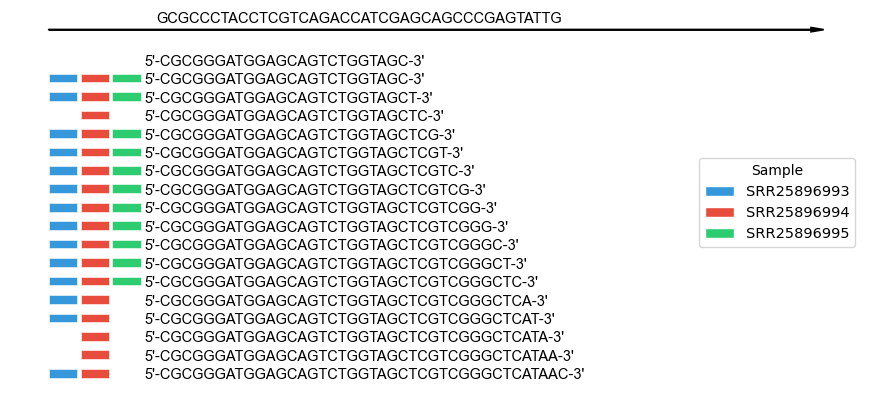

In [24]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=20)

arial_font_in = fm.FontProperties(fname="arial.ttf", size=13)

sequences = [
    ("CGCGGGATGGAGCAGTCTGGTAGC", [ "white"]), 
    ("CGCGGGATGGAGCAGTCTGGTAGC", [ "#3498db", "#e74c3c","#2ecc71"]),   # blue-red-green
    ("CGCGGGATGGAGCAGTCTGGTAGCT", [ "#3498db", "#e74c3c","#2ecc71"]),             # blue-green
    ("CGCGGGATGGAGCAGTCTGGTAGCTC", ['white','#e74c3c']),                       # red only
    ("CGCGGGATGGAGCAGTCTGGTAGCTCG", [ "#3498db", "#e74c3c","#2ecc71"]),# blue-green-lightgreen
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGT", [ "#3498db", "#e74c3c","#2ecc71"]), 
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTC", [ "#3498db", "#e74c3c","#2ecc71"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCG", [ "#3498db", "#e74c3c","#2ecc71"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCGG", [ "#3498db", "#e74c3c","#2ecc71"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGG", [ "#3498db", "#e74c3c","#2ecc71"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGC", [ "#3498db", "#e74c3c","#2ecc71"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCT", [ "#3498db", "#e74c3c","#2ecc71"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTC", [ "#3498db", "#e74c3c","#2ecc71"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCA", [ "#3498db", "#e74c3c"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCAT", [ "#3498db", "#e74c3c"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATA", [ "white", "#e74c3c"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAA", [ "white", "#e74c3c"]),
    ("CGCGGGATGGAGCAGTCTGGTAGCTCGTCGGGCTCATAAC", [ "#3498db", "#e74c3c"]),
      #GCGCCCTACCTCGTCAGACCATCGAGCAGCCCGAGTATTG
]

fig, ax = plt.subplots(figsize=(11, 5))
ax.axis('off')
# ax.set_aspect('equal')

ax.arrow(0, 0.75, 24, 0, head_width=0.1, head_length=0.4, fc="black", ec="black", lw=1.2, color="black")
ref_seq = "GCGCCCTACCTCGTCAGACCATCGAGCAGCCCGAGTATTG"



ax.text(3.4, 1, ref_seq, color='black',  fontsize=10.5, fontproperties=arial_font, va='center')


# for i in range(25):  # draw a few match bars
#     x = 4 + i * 0.5383
#     ax.text(x, 0.33, "|", color='gray',  fontsize=22.5, fontproperties=arial_font, ha='center')

for i, (seq, colors) in enumerate(sequences):
    y = -i * 0.43
    print(y)
 
    for j, color in enumerate(colors):
        ax.add_patch(plt.Rectangle(( j, y-0.05), 0.9, 0.2, color=color, ec='white', lw=0.4))

    ax.text(3.0, y, f"5'-{seq}-3'", va='center', ha='left',
            fontsize=10.5, fontproperties=arial_font)
legend_items = {
    '#3498db': "SRR25896993",
    '#e74c3c': "SRR25896994",
    '#2ecc71': "SRR25896995"
}
handles = [patches.Patch(color=c, label=legend_items[c], ec='white') for c in legend_items]
ax.legend(handles=handles, title="Sample", loc='center right', fontsize=10.5, frameon=True)

# ax.set_xlim(-1, 10)        # adjust for your total width
# ax.set_ylim(-10, 1)  
plt.tight_layout()
# plt.show()
plt.savefig("figure8_C.pdf", format="pdf", bbox_inches="tight")
